<a href="https://colab.research.google.com/github/AlexMoffatt10/COM7019/blob/main/COM7021.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

DATA_PATH = Path("data/[5442] EcoMoveMobility.xlsx")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)


PALETTE = ["#eb6834", "#2a78d6", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
MODE_ORDER = ["Metro", "Tram", "Bus", "Park and Ride", "Bike Share", "E-Scooter"]
MODE_COLOURS = dict(zip(MODE_ORDER, PALETTE))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

CHARCOAL, ORANGE, ORANGE_DARK, ORANGE_LIGHT = "#3a3a3a", "#eb6834", "#c4501a", "#f6c3a8"
POS, NEG = CHARCOAL, ORANGE_DARK

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "axes.edgecolor": GRID, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", facecolor="white")
    plt.show()


In [4]:

   DATA_PATH = Path("[5442] EcoMoveMobility.xlsx")
   raw = pd.read_excel(DATA_PATH)
   print("Shape:", raw.shape)
   raw.head()

Shape: (5000, 18)


,Record_ID,Date,City,Country,Transport_Mode,Route_Type,Weather,Event_Day,Passengers,Trips,Average_Delay_Minutes,On_Time_Percentage,Ticket_Revenue_EUR,Operating_Cost_EUR,CO2_Saved_KG,Energy_Consumption_KWh,Customer_Rating,Accessibility_Complaints
0,EM-00001,45747,Paris,France,Tram,Tourist Zone,Cloudy,Yes,22946,101,3.2,85.1,58846.34,47796.73,2005.0,1446.4,4.4,26
1,EM-00002,45717,Paris,France,Tram,University Area,Cloudy,No,9417,59,1.5,90.1,24578.85,20708.01,824.3,495.1,4.7,7
2,EM-00003,45882,Rotterdam,Netherlands,Tram,Airport Connector,Clear,No,6467,38,3.4,87.9,15168.68,14129.41,693.1,405.8,4.4,7
3,EM-00004,45504,Lyon,France,Tram,University Area,Clear,Yes,5218,33,6.9,74.5,14172.20,11945.52,600.1,278.1,3.9,7
4,EM-00005,45578,Amsterdam,Netherlands,Metro,Tourist Zone,Cloudy,No,10258,19,3.6,83.2,27534.92,28846.82,1392.4,580.5,4.4,12


In [5]:

raw.info()
print("\nMissing values per column:\n", raw.isna().sum())
print("\nDuplicate Record_IDs:", raw["Record_ID"].duplicated().sum())
print("Fully duplicated rows:", raw.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Record_ID                 5000 non-null   object 
 1   Date                      5000 non-null   int64  
 2   City                      5000 non-null   object 
 3   Country                   5000 non-null   object 
 4   Transport_Mode            5000 non-null   object 
 5   Route_Type                5000 non-null   object 
 6   Weather                   5000 non-null   object 
 7   Event_Day                 5000 non-null   object 
 8   Passengers                5000 non-null   int64  
 9   Trips                     5000 non-null   int64  
 10  Average_Delay_Minutes     5000 non-null   float64
 11  On_Time_Percentage        5000 non-null   float64
 12  Ticket_Revenue_EUR        5000 non-null   float64
 13  Operating_Cost_EUR        5000 non-null   float64
 14  CO2_Save

In [6]:

raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Date,5000.0,45653.87,209.72,45292.00,45474.00,45648.00,45835.00,46022.00
Passengers,5000.0,8181.94,10018.72,64.00,1411.75,4398.00,10077.50,66416.00
Trips,5000.0,121.77,155.79,11.00,36.00,52.00,106.00,1048.00
Average_Delay_Minutes,5000.0,4.35,2.39,0.00,2.60,4.40,6.00,12.50
On_Time_Percentage,5000.0,82.06,7.93,55.00,76.50,82.00,87.90,99.00
Ticket_Revenue_EUR,5000.0,22328.12,28822.41,90.93,3280.33,11190.02,26329.65,204386.05
Operating_Cost_EUR,5000.0,22422.00,26114.32,978.37,7189.86,11638.28,22732.98,178936.39
CO2_Saved_KG,5000.0,896.39,1261.16,8.30,126.85,338.30,1009.48,8884.10
Energy_Consumption_KWh,5000.0,466.81,564.22,0.00,85.20,269.70,599.62,3856.30
Customer_Rating,5000.0,4.01,0.40,2.70,3.70,4.00,4.30,4.90


In [7]:
for col in ["City", "Country", "Transport_Mode", "Route_Type", "Weather", "Event_Day"]:
    print(f"{col}: {raw[col].nunique()} levels -> {sorted(raw[col].unique())}")


print("\nCities mapped to more than one country:",
      (raw.groupby("City")["Country"].nunique() > 1).sum())

City: 12 levels -> ['Amsterdam', 'Barcelona', 'Berlin', 'Hamburg', 'Lyon', 'Madrid', 'Milan', 'Munich', 'Paris', 'Rome', 'Rotterdam', 'Vienna']
Country: 6 levels -> ['Austria', 'France', 'Germany', 'Italy', 'Netherlands', 'Spain']
Transport_Mode: 6 levels -> ['Bike Share', 'Bus', 'E-Scooter', 'Metro', 'Park and Ride', 'Tram']
Route_Type: 6 levels -> ['Airport Connector', 'Central Route', 'Commuter Corridor', 'Suburban Feeder', 'Tourist Zone', 'University Area']
Weather: 6 levels -> ['Clear', 'Cloudy', 'Heatwave', 'Rain', 'Snow', 'Windy']
Event_Day: 2 levels -> ['No', 'Yes']

Cities mapped to more than one country: 0


In [8]:
df = raw.copy()

df["Date"] = pd.to_datetime(df["Date"], unit="D", origin="1899-12-30")
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df["Month_Num"] = df["Date"].dt.month

for col in ["City", "Country", "Transport_Mode", "Route_Type", "Weather", "Event_Day"]:
    df[col] = df[col].str.strip().astype("category")

df["Net_Result_EUR"] = df["Ticket_Revenue_EUR"] - df["Operating_Cost_EUR"]
df["Cost_Recovery_Pct"] = df["Ticket_Revenue_EUR"] / df["Operating_Cost_EUR"] * 100
df["Passengers_per_Trip"] = df["Passengers"] / df["Trips"]
df["Complaints_per_10k"] = df["Accessibility_Complaints"] / df["Passengers"] * 10_000
df["CO2_per_Passenger_KG"] = df["CO2_Saved_KG"] / df["Passengers"]

assert df["On_Time_Percentage"].between(0, 100).all()
assert df["Customer_Rating"].between(1, 5).all()
assert (df["Passengers"] > 0).all() and (df["Trips"] > 0).all()
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Records with zero energy use:", (df["Energy_Consumption_KWh"] == 0).sum(),
      "(by mode)", df.loc[df["Energy_Consumption_KWh"] == 0, "Transport_Mode"].value_counts().to_dict())

Date range: 2024-01-01 to 2025-12-31
Records with zero energy use: 759 (by mode) {'Bike Share': 759, 'Bus': 0, 'E-Scooter': 0, 'Metro': 0, 'Park and Ride': 0, 'Tram': 0}


In [9]:

num_cols = ["Passengers", "Average_Delay_Minutes", "Ticket_Revenue_EUR",
            "Operating_Cost_EUR", "Accessibility_Complaints"]
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum()
print(outliers.rename("IQR outliers"))
print("\nShare of passenger outliers that are Metro:",
      f"{(df.loc[df['Passengers'] > q3['Passengers'] + 1.5 * iqr['Passengers'], 'Transport_Mode'] == 'Metro').mean():.0%}")

Passengers                  525
Average_Delay_Minutes        11
Ticket_Revenue_EUR          591
Operating_Cost_EUR          780
Accessibility_Complaints    472
Name: IQR outliers, dtype: int64

Share of passenger outliers that are Metro: 100%


In [10]:

kpi = {
    "Passengers": df["Passengers"].sum(),
    "Ticket revenue (EUR m)": df["Ticket_Revenue_EUR"].sum() / 1e6,
    "Operating cost (EUR m)": df["Operating_Cost_EUR"].sum() / 1e6,
    "Net result (EUR m)": df["Net_Result_EUR"].sum() / 1e6,
    "Mean on-time %": df["On_Time_Percentage"].mean(),
    "Mean delay (min)": df["Average_Delay_Minutes"].mean(),
    "Mean rating": df["Customer_Rating"].mean(),
    "CO2 saved (tonnes)": df["CO2_Saved_KG"].sum() / 1000,
    "Complaints per 10k passengers": df["Accessibility_Complaints"].sum() / df["Passengers"].sum() * 1e4,
}
pd.Series(kpi).round(2).to_frame("Value")

,Value
Passengers,40909721.00
Ticket revenue (EUR m),111.64
Operating cost (EUR m),112.11
Net result (EUR m),-0.47
Mean on-time %,82.06
Mean delay (min),4.35
Mean rating,4.01
CO2 saved (tonnes),4481.97
Complaints per 10k passengers,15.32


In [11]:
def summarise(group):
    g = df.groupby(group, observed=True).agg(
        Records=("Record_ID", "count"),
        Passengers=("Passengers", "sum"),
        Revenue=("Ticket_Revenue_EUR", "sum"),
        Cost=("Operating_Cost_EUR", "sum"),
        Delay=("Average_Delay_Minutes", "mean"),
        OnTime=("On_Time_Percentage", "mean"),
        Rating=("Customer_Rating", "mean"),
        Complaints=("Accessibility_Complaints", "sum"),
        CO2_t=("CO2_Saved_KG", lambda s: s.sum() / 1000),
    )
    g["Net"] = g["Revenue"] - g["Cost"]
    g["Cost_Recovery_%"] = g["Revenue"] / g["Cost"] * 100
    g["Complaints_per_10k"] = g["Complaints"] / g["Passengers"] * 1e4
    return g

mode_tbl = summarise("Transport_Mode").reindex(MODE_ORDER)
city_tbl = summarise("City").sort_values("Passengers", ascending=False)
mode_tbl.round(2)

,Records,Passengers,Revenue,Cost,Delay,OnTime,Rating,Complaints,CO2_t,Net,Cost_Recovery_%,Complaints_per_10k
Transport_Mode,,,,,,,,,,,,
Metro,1047,25757522,73334170.86,69029226.89,3.73,84.09,4.09,38240,3150.92,4304943.97,106.24,14.85
Tram,761,6380878,15666167.52,13355946.79,4.79,80.63,3.94,9621,646.92,2310220.73,117.30,15.08
Bus,1375,5073394,12002118.92,11992457.44,6.58,74.92,3.74,8859,414.16,9661.48,100.08,17.46
Park and Ride,585,3265220,10066523.80,8283138.05,5.17,79.46,3.90,5183,199.19,1783385.75,121.53,15.87
Bike Share,759,268765,310355.03,5912287.24,1.62,90.85,4.35,457,49.13,-5601932.21,5.25,17.00
E-Scooter,473,163942,261278.13,3536959.56,1.94,89.71,4.29,301,21.65,-3275681.43,7.39,18.36


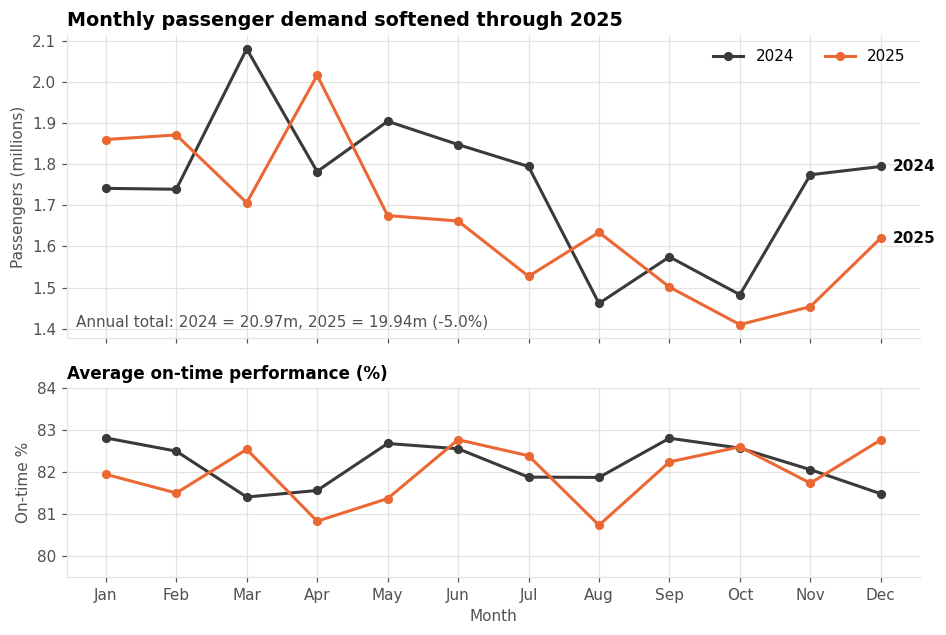

In [12]:
monthly = df.groupby(["Year", "Month_Num"]).agg(
    Passengers=("Passengers", "sum"), OnTime=("On_Time_Percentage", "mean")).reset_index()
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True,
                               gridspec_kw={"height_ratios": [1.6, 1]})
for (yr, colour) in [(2024, CHARCOAL), (2025, ORANGE)]:
    m = monthly[monthly["Year"] == yr]
    ax1.plot(m["Month_Num"], m["Passengers"] / 1e6, color=colour, lw=2, marker="o", ms=5, label=str(yr))
    ax1.annotate(str(yr), (12, m["Passengers"].iloc[-1] / 1e6), xytext=(8, 0),
                 textcoords="offset points", va="center", color=INK, fontweight="bold")
    ax2.plot(m["Month_Num"], m["OnTime"], color=colour, lw=2, marker="o", ms=5)
ax1.set_title("Monthly passenger demand softened through 2025")
ax1.set_ylabel("Passengers (millions)")
ax1.legend(loc="upper right", ncol=2)
y24, y25 = monthly.groupby("Year")["Passengers"].sum() / 1e6  # unrounded, so the % change is exact
ax1.text(0.01, 0.04, f"Annual total: 2024 = {y24:.2f}m, 2025 = {y25:.2f}m ({(y25 / y24 - 1):+.1%})",
         transform=ax1.transAxes, color=MUTED)
ax2.set_title("Average on-time performance (%)", fontsize=11)
ax2.set_ylabel("On-time %")
ax2.set_xticks(range(1, 13), months)
ax2.set_xlabel("Month")
ax2.set_ylim(79.5, 84)
save(fig, "fig01_time_series_demand_reliability")

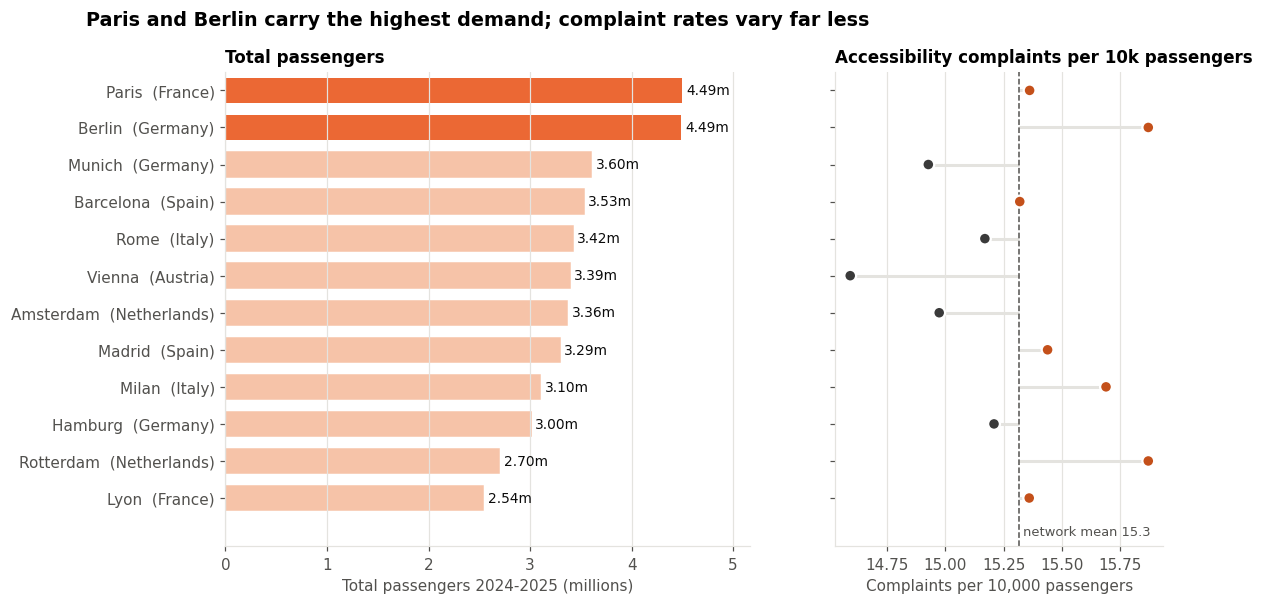

In [13]:
ct = city_tbl.sort_values("Passengers")
country_of = df.groupby("City", observed=True)["Country"].first()
labels = [f"{c}  ({country_of[c]})" for c in ct.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5.6), sharey=True,
                               gridspec_kw={"width_ratios": [1.6, 1]})
bars = ax1.barh(labels, ct["Passengers"] / 1e6, color=ORANGE, height=0.66)
top2 = ct.index[-2:]
for b, city in zip(bars, ct.index):
    if city not in top2:
        b.set_color(ORANGE_LIGHT)
ax1.bar_label(bars, fmt="%.2fm", padding=3, color=INK, fontsize=9)
fig.suptitle("Paris and Berlin carry the highest demand; complaint rates vary far less", x=0.01, ha="left", fontweight="bold", fontsize=12.5)
ax1.set_title("Total passengers", fontsize=11)
ax1.set_xlabel("Total passengers 2024-2025 (millions)")
ax1.grid(axis="y", visible=False)
ax1.set_xlim(0, ct["Passengers"].max() / 1e6 * 1.15)

mean_rate = df["Accessibility_Complaints"].sum() / df["Passengers"].sum() * 1e4
ax2.hlines(labels, mean_rate, ct["Complaints_per_10k"], color=GRID, lw=2)
ax2.scatter(ct["Complaints_per_10k"], labels, s=60, zorder=3,
            color=[ORANGE_DARK if v > mean_rate else CHARCOAL for v in ct["Complaints_per_10k"]],
            edgecolor="white", linewidth=1.5)
ax2.axvline(mean_rate, color=MUTED, ls="--", lw=1)
ax2.text(mean_rate, -0.9, f" network mean {mean_rate:.1f}", color=MUTED, fontsize=8.5, va="center")
ax2.set_ylim(-1.3, len(ct) - 0.5)
ax2.set_title("Accessibility complaints per 10k passengers", fontsize=11)
ax2.set_xlabel("Complaints per 10,000 passengers")
ax2.grid(axis="y", visible=False)
save(fig, "fig02_city_comparison")

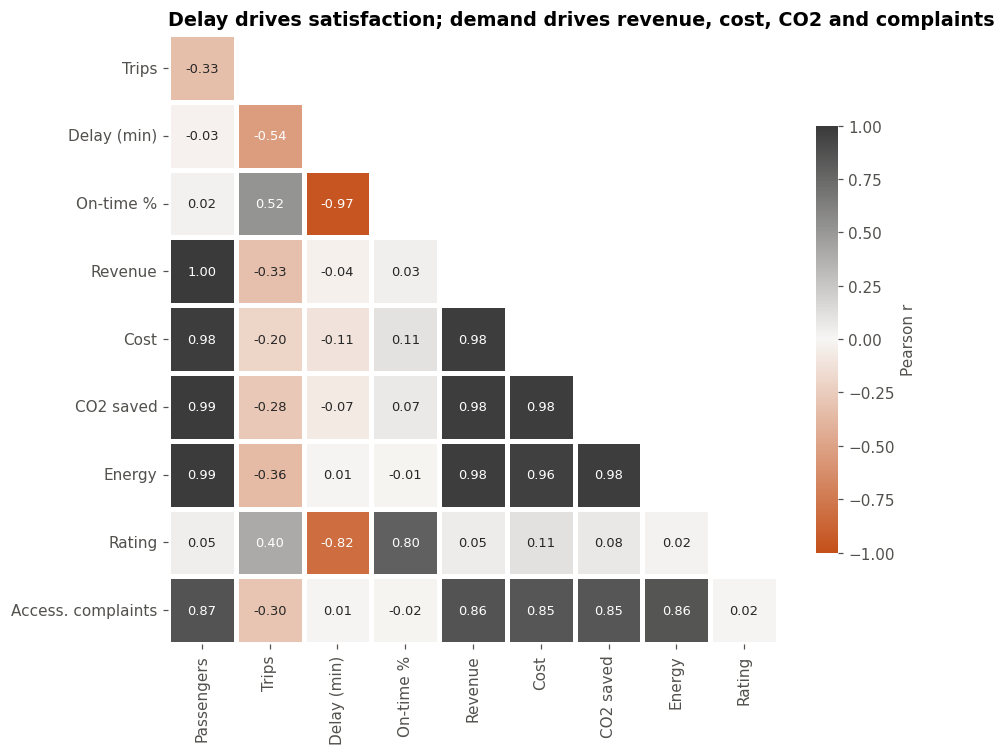

In [14]:
corr_cols = {
    "Passengers": "Passengers", "Trips": "Trips", "Average_Delay_Minutes": "Delay (min)",
    "On_Time_Percentage": "On-time %", "Ticket_Revenue_EUR": "Revenue", "Operating_Cost_EUR": "Cost",
    "CO2_Saved_KG": "CO2 saved", "Energy_Consumption_KWh": "Energy", "Customer_Rating": "Rating",
    "Accessibility_Complaints": "Access. complaints",
}
corr = df[list(corr_cols)].rename(columns=corr_cols).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
corr, mask = corr.iloc[1:, :-1], mask[1:, :-1]
fig, ax = plt.subplots(figsize=(9, 7.2))
sns.heatmap(corr, mask=mask, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("orange_charcoal", [ORANGE_DARK, "#f7f6f4", CHARCOAL]),
            vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 8.5},
            linewidths=2, linecolor="white", square=True, cbar_kws={"shrink": 0.7, "label": "Pearson r"}, ax=ax)
ax.set_title("Delay drives satisfaction; demand drives revenue, cost, CO2 and complaints")
ax.grid(False)
save(fig, "fig03_correlation_heatmap")

Rating = 4.61 -0.138 x delay  (r = -0.82, p < 0.001)
Each extra minute of delay costs about 0.14 rating points


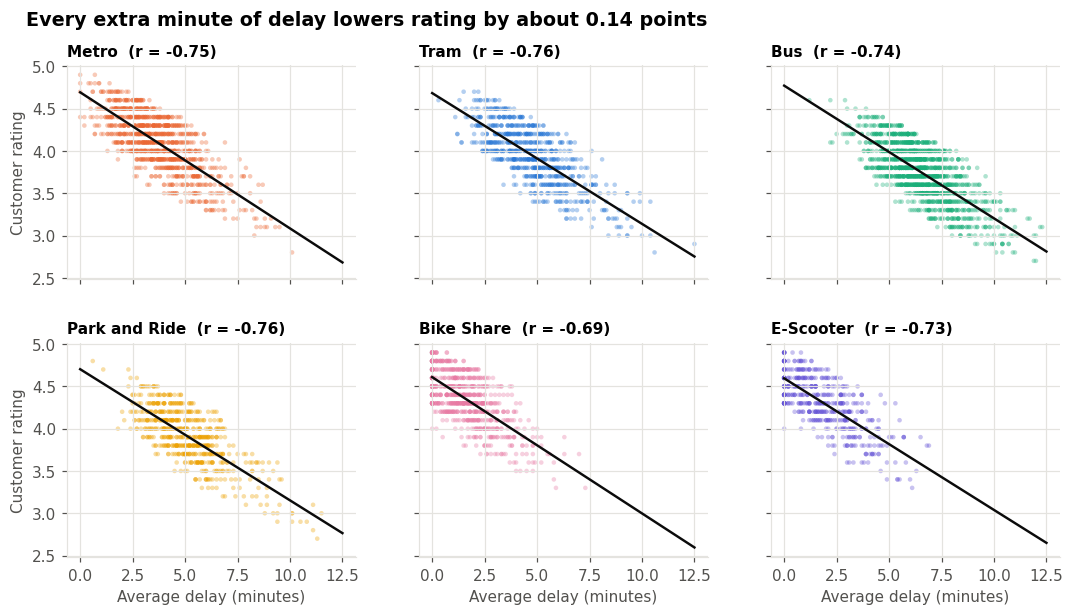

In [15]:
slope, intercept, r, p, _ = stats.linregress(df["Average_Delay_Minutes"], df["Customer_Rating"])
print(f"Rating = {intercept:.2f} {slope:+.3f} x delay  (r = {r:.2f}, p {'< 0.001' if p < 0.001 else '= ' + format(p, '.3f')})")
print(f"Each extra minute of delay costs about {abs(slope):.2f} rating points")

g = sns.FacetGrid(df, col="Transport_Mode", col_order=MODE_ORDER, col_wrap=3, height=2.6, aspect=1.25)
for ax, mode in zip(g.axes.flat, MODE_ORDER):
    sub = df[df["Transport_Mode"] == mode]
    ax.scatter(sub["Average_Delay_Minutes"], sub["Customer_Rating"], s=9, alpha=0.35,
               color=MODE_COLOURS[mode], edgecolor="none")
    s2, i2, r2, *_ = stats.linregress(sub["Average_Delay_Minutes"], sub["Customer_Rating"])
    xs = np.linspace(0, 12.5, 20)
    ax.plot(xs, i2 + s2 * xs, color=INK, lw=1.6)
    ax.set_title(f"{mode}  (r = {r2:.2f})", fontsize=10)
g.set_axis_labels("Average delay (minutes)", "Customer rating")
g.figure.suptitle(f"Every extra minute of delay lowers rating by about {abs(slope):.2f} points",
                  x=0.01, ha="left", y=1.03, fontweight="bold", fontsize=12.5)
g.savefig(FIG_DIR / "fig04_delay_vs_rating_scatter.png", facecolor="white")
plt.show()

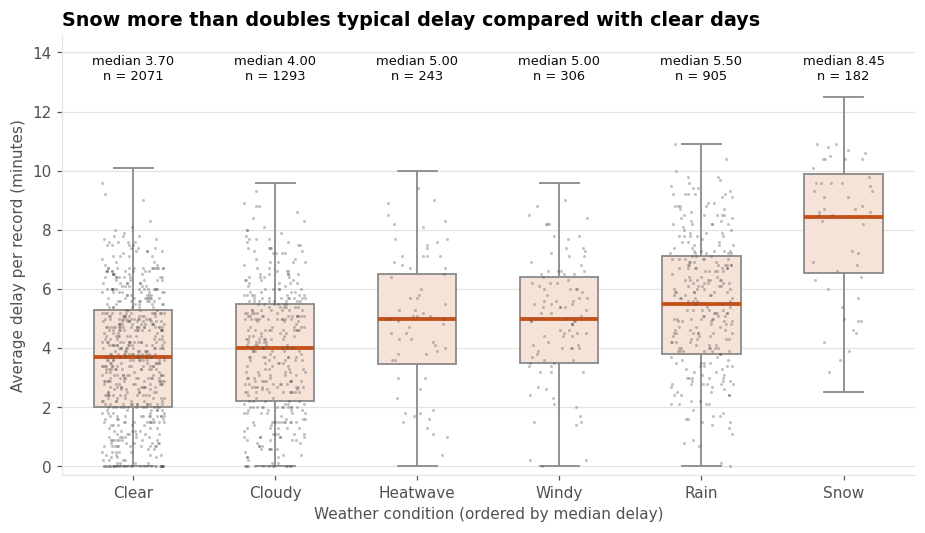

In [16]:
w_order = df.groupby("Weather", observed=True)["Average_Delay_Minutes"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.2))
sns.boxplot(data=df, x="Weather", y="Average_Delay_Minutes", order=w_order, color="#fbe1d3",
            width=0.55, fliersize=0, linewidth=1.2, ax=ax,
            medianprops={"color": ORANGE_DARK, "lw": 2.5})
sns.stripplot(data=df.sample(1500, random_state=1), x="Weather", y="Average_Delay_Minutes",
              order=w_order, color=MUTED, size=2, alpha=0.35, jitter=0.22, ax=ax)
med = df.groupby("Weather", observed=True)["Average_Delay_Minutes"].median()
cnt = df["Weather"].value_counts()
for i, w in enumerate(w_order):
    ax.text(i, 13.1, f"median {med[w]:.2f}\nn = {cnt[w]}", ha="center", fontsize=8.5, color=INK)
ax.set_ylim(-0.3, 14.6)
ax.set_title("Snow more than doubles typical delay compared with clear days")
ax.set_xlabel("Weather condition (ordered by median delay)")
ax.set_ylabel("Average delay per record (minutes)")
save(fig, "fig05_delay_distribution_weather")

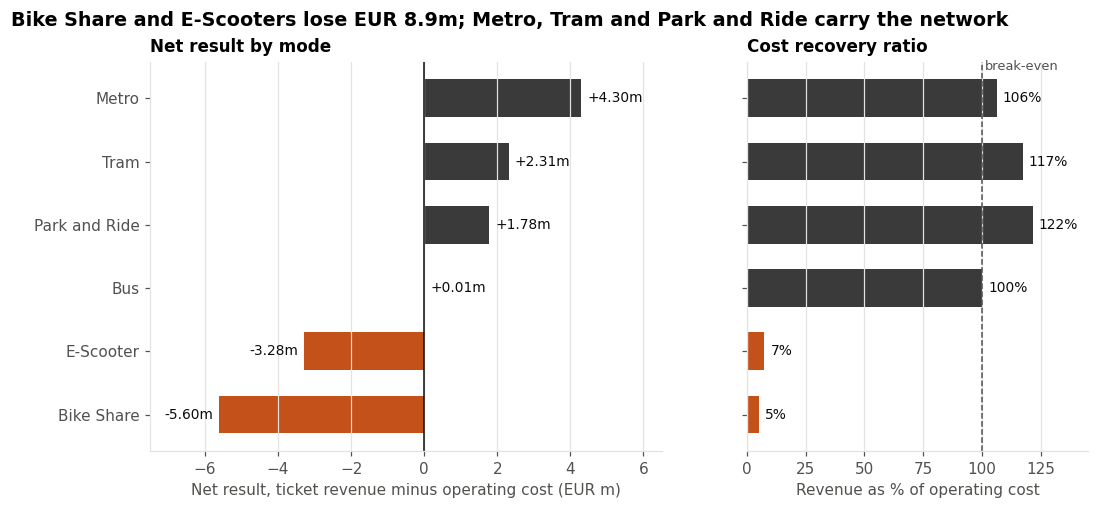

In [17]:
mt = mode_tbl.sort_values("Net")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True,
                               gridspec_kw={"width_ratios": [1.5, 1]})
bars = ax1.barh(mt.index, mt["Net"] / 1e6, color=[POS if v >= 0 else NEG for v in mt["Net"]], height=0.6)
ax1.bar_label(bars, labels=[f"{v / 1e6:+.2f}m" for v in mt["Net"]], padding=4, fontsize=9, color=INK)
ax1.axvline(0, color=INK, lw=1)
ax1.set_xlim(-7.5, 6.5)
fig.suptitle("Bike Share and E-Scooters lose EUR 8.9m; Metro, Tram and Park and Ride carry the network", x=0.01, ha="left", fontweight="bold", fontsize=12.5)
ax1.set_title("Net result by mode", fontsize=11)
ax1.set_xlabel("Net result, ticket revenue minus operating cost (EUR m)")
ax1.grid(axis="y", visible=False)

bars2 = ax2.barh(mt.index, mt["Cost_Recovery_%"], color=[POS if v >= 100 else NEG for v in mt["Cost_Recovery_%"]], height=0.6)
ax2.bar_label(bars2, fmt="%.0f%%", padding=4, fontsize=9, color=INK)
ax2.axvline(100, color=MUTED, ls="--", lw=1)
ax2.text(101, 5.45, "break-even", color=MUTED, fontsize=8.5)
ax2.set_xlim(0, 145)
ax2.set_title("Cost recovery ratio", fontsize=11)
ax2.set_xlabel("Revenue as % of operating cost")
ax2.grid(axis="y", visible=False)
save(fig, "fig06_mode_financial_performance")

Mode means:
 Transport_Mode
Metro            84.1
Tram             80.6
Bus              74.9
Park and Ride    79.5
Bike Share       90.9
E-Scooter        89.7
Name: On_Time_Percentage, dtype: float64
City means: lowest Lyon 81.3 | highest Barcelona 82.8
City spread within each mode (max - min):
 Transport_Mode
Metro            2.3
Tram             3.6
Bus              1.7
Park and Ride    2.3
Bike Share       3.0
E-Scooter        3.5
dtype: float64


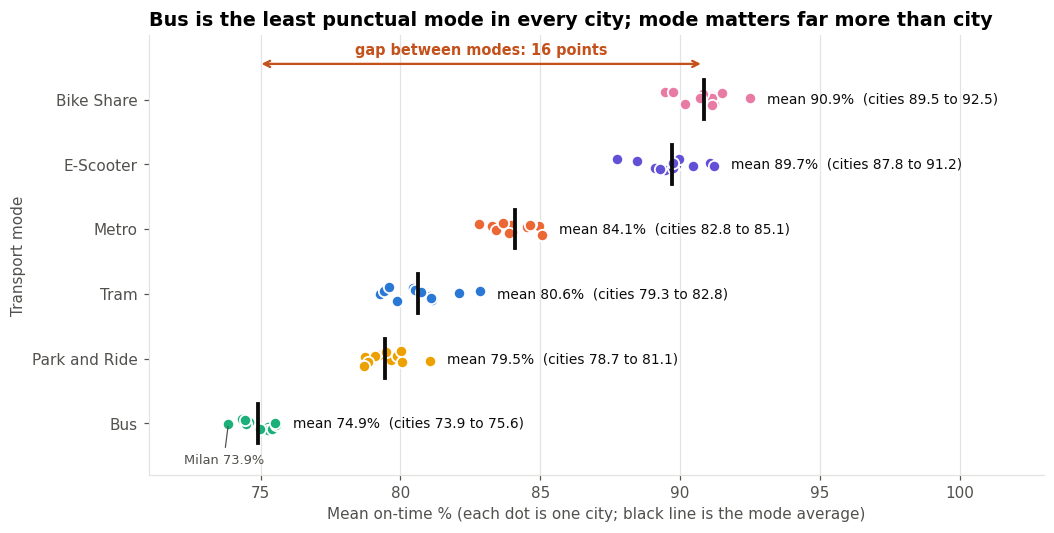

In [18]:
pivot = df.pivot_table(index="City", columns="Transport_Mode", values="On_Time_Percentage",
                       aggfunc="mean", observed=True)[MODE_ORDER]
mode_mean = df.groupby("Transport_Mode", observed=True)["On_Time_Percentage"].mean().reindex(MODE_ORDER)
city_mean = df.groupby("City", observed=True)["On_Time_Percentage"].mean().sort_values()
row_order = mode_mean.sort_values().index.tolist()          # worst mode at the bottom
print("Mode means:\n", mode_mean.round(1))
print("City means: lowest", city_mean.index[0], round(city_mean.iloc[0], 1),
      "| highest", city_mean.index[-1], round(city_mean.iloc[-1], 1))
print("City spread within each mode (max - min):\n", (pivot.max() - pivot.min()).round(1))

fig, ax = plt.subplots(figsize=(10.5, 5.2))
rng = np.random.default_rng(3)
for y, mode in enumerate(row_order):
    vals = pivot[mode]
    jitter = rng.uniform(-0.12, 0.12, len(vals))
    ax.scatter(vals, y + jitter, s=55, color=MODE_COLOURS[mode], edgecolor="white", linewidth=1.2, zorder=3)
    ax.plot([mode_mean[mode]] * 2, [y - 0.3, y + 0.3], color=INK, lw=2.5, zorder=4)
    ax.text(vals.max() + 0.6, y, f"mean {mode_mean[mode]:.1f}%  (cities {vals.min():.1f} to {vals.max():.1f})",
            va="center", fontsize=9, color=INK)
bus = pivot["Bus"]
ax.annotate(f"{bus.idxmin()} {bus.min():.1f}%", (bus.min(), 0), xytext=(bus.min() - 1.6, -0.62),
            fontsize=8.5, color=MUTED, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
gap = mode_mean.max() - mode_mean.min()
ax.annotate("", xy=(mode_mean.max(), len(row_order) - 0.45), xytext=(mode_mean.min(), len(row_order) - 0.45),
            arrowprops=dict(arrowstyle="<->", color=ORANGE_DARK, lw=1.5))
ax.text((mode_mean.max() + mode_mean.min()) / 2, len(row_order) - 0.3,
        f"gap between modes: {gap:.0f} points", ha="center", color=ORANGE_DARK, fontweight="bold", fontsize=9.5)
ax.set_yticks(range(len(row_order)), row_order)
ax.set_ylim(-0.8, len(row_order))
ax.set_xlim(71, 103)
ax.set_xlabel("Mean on-time % (each dot is one city; black line is the mode average)")
ax.set_ylabel("Transport mode")
ax.grid(axis="y", visible=False)
ax.set_title("Bus is the least punctual mode in every city; mode matters far more than city")
save(fig, "fig07_city_mode_ontime_dotplot")

           Delay  OnTime  Rating  PaxPerRecord
Event_Day                                     
No          4.22   82.49    4.02       7968.86
Yes         5.53   78.21    3.87      10057.93
Welch t-test on delay: t = 11.84, p = 2.5e-29


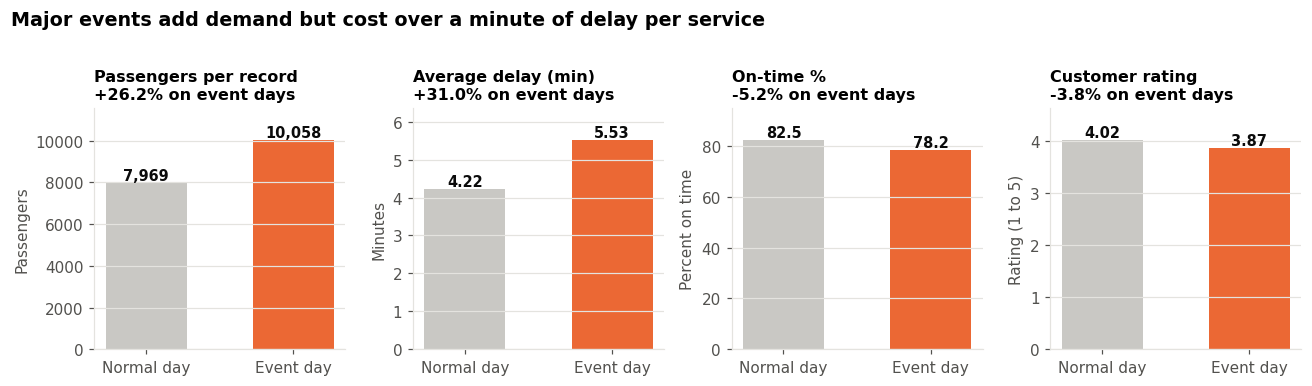

In [19]:
ev = df.groupby("Event_Day", observed=True).agg(
    Delay=("Average_Delay_Minutes", "mean"), OnTime=("On_Time_Percentage", "mean"),
    Rating=("Customer_Rating", "mean"), PaxPerRecord=("Passengers", "mean")).reindex(["No", "Yes"])
t_delay = stats.ttest_ind(df.loc[df.Event_Day == "Yes", "Average_Delay_Minutes"],
                          df.loc[df.Event_Day == "No", "Average_Delay_Minutes"], equal_var=False)
print(ev.round(2))
print(f"Welch t-test on delay: t = {t_delay.statistic:.2f}, p = {t_delay.pvalue:.1e}")

metrics = [("PaxPerRecord", "Passengers per record", "{:,.0f}"), ("Delay", "Average delay (min)", "{:.2f}"),
           ("OnTime", "On-time %", "{:.1f}"), ("Rating", "Customer rating", "{:.2f}")]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, (col, title, fmt) in zip(axes, metrics):
    vals = ev[col].values
    ax.bar(["Normal day", "Event day"], vals, color=["#c9c8c4", ORANGE], width=0.55)
    for x, v in enumerate(vals):
        ax.text(x, v, fmt.format(v), ha="center", va="bottom", fontsize=9.5, color=INK, fontweight="bold")
    change = vals[1] / vals[0] - 1
    ax.set_title(f"{title}\n{change:+.1%} on event days", fontsize=10.5)
    ax.set_ylim(0, max(vals) * 1.15)  # bars always start at zero
    ax.set_ylabel({"PaxPerRecord": "Passengers", "Delay": "Minutes", "OnTime": "Percent on time", "Rating": "Rating (1 to 5)"}[col])
    ax.grid(axis="x", visible=False)
fig.suptitle("Major events add demand but cost over a minute of delay per service",
             x=0.01, ha="left", fontweight="bold", fontsize=12.5, y=1.02)
fig.tight_layout()
save(fig, "fig08_event_day_impact")

CO2 by year (t): {2024: 2301.0, 2025: 2181.0}


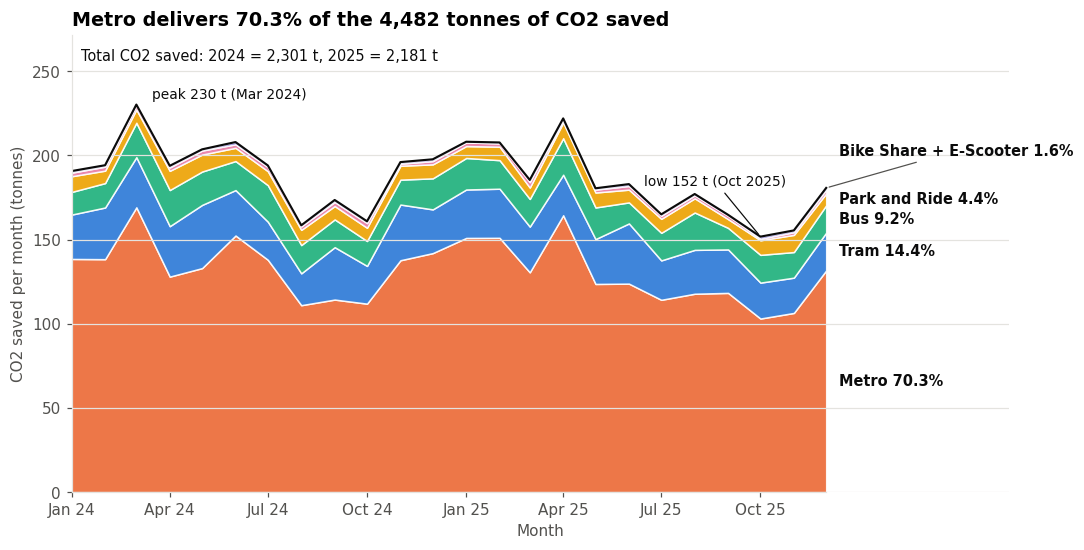

Transport_Mode
Metro            0.122
Tram             0.101
Bus              0.082
Park and Ride    0.061
Bike Share       0.183
E-Scooter        0.132
Name: CO2 saved per passenger (kg), dtype: float64


In [20]:
co2 = (df.pivot_table(index="Month", columns="Transport_Mode", values="CO2_Saved_KG",
                      aggfunc="sum", observed=True)[MODE_ORDER] / 1000)
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.stackplot(co2.index, [co2[m] for m in MODE_ORDER], labels=MODE_ORDER,
             colors=[MODE_COLOURS[m] for m in MODE_ORDER], alpha=0.9, edgecolor="white", linewidth=1)
total = co2.sum(axis=1)
ax.plot(co2.index, total, color=INK, lw=1.4)
share = (co2.sum() / co2.sum().sum() * 100).round(1)

last = co2.iloc[-1]
cum = last.cumsum()
x_lab = co2.index[-1] + pd.Timedelta(days=12)
for m in ["Metro", "Tram", "Bus", "Park and Ride"]:
    mid = cum[m] - last[m] / 2
    ax.text(x_lab, mid, f"{m} {share[m]}%", va="center", fontsize=9.5, color=INK, fontweight="bold")
small = share["Bike Share"] + share["E-Scooter"]
ax.annotate(f"Bike Share + E-Scooter {small:.1f}%", xy=(co2.index[-1], cum["E-Scooter"]),
            xytext=(x_lab, cum["E-Scooter"] + 22), fontsize=9.5, color=INK, fontweight="bold", va="center",
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))

pk, tr = total.idxmax(), total.idxmin()
ax.annotate(f"peak {total[pk]:.0f} t ({pk:%b %Y})", (pk, total[pk]), xytext=(10, 4),
            textcoords="offset points", ha="left", fontsize=9, color=INK)
ax.annotate(f"low {total[tr]:.0f} t ({tr:%b %Y})", (tr, total[tr]), xytext=(-30, 34),
            textcoords="offset points", ha="center", fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK, lw=0.8))
yr = total.groupby(total.index.year).sum()
ax.text(0.01, 0.97, f"Total CO2 saved: 2024 = {yr[2024]:,.0f} t, 2025 = {yr[2025]:,.0f} t",
        transform=ax.transAxes, va="top", color=INK, fontsize=9.5)
ax.set_title(f"Metro delivers {share['Metro']}% of the {co2.sum().sum():,.0f} tonnes of CO2 saved")
ax.set_ylabel("CO2 saved per month (tonnes)")
ax.set_xlabel("Month")
ax.set_ylim(0, total.max() * 1.18)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %y"))
ax.set_xlim(co2.index[0], co2.index[-1] + pd.Timedelta(days=170))
ax.set_xticks(pd.date_range(co2.index[0], co2.index[-1], freq="3MS"))
ax.grid(axis="x", visible=False)
ax.spines["bottom"].set_bounds(*plt.matplotlib.dates.date2num([co2.index[0], co2.index[-1]]))
print("CO2 by year (t):", yr.round(0).to_dict())
save(fig, "fig09_co2_saved_stacked_area")

print((df.groupby("Transport_Mode", observed=True)["CO2_Saved_KG"].sum()
       / df.groupby("Transport_Mode", observed=True)["Passengers"].sum()).reindex(MODE_ORDER).round(3)
      .rename("CO2 saved per passenger (kg)"))

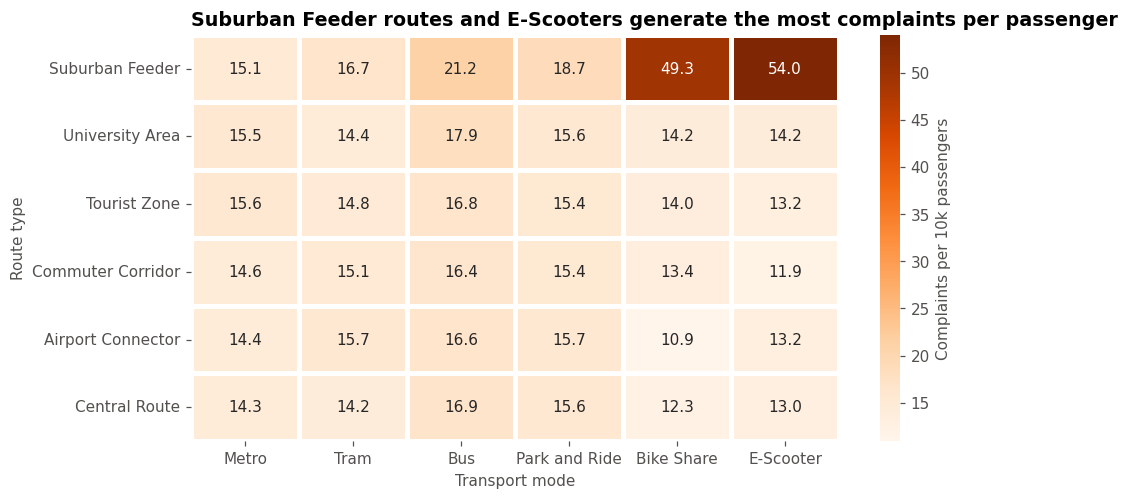

In [21]:
acc = df.groupby(["Route_Type", "Transport_Mode"], observed=True).agg(
    C=("Accessibility_Complaints", "sum"), P=("Passengers", "sum"))
acc_rate = (acc["C"] / acc["P"] * 1e4).unstack()[MODE_ORDER]
acc_rate = acc_rate.loc[acc_rate.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.heatmap(acc_rate, cmap="Oranges", annot=True, fmt=".1f", linewidths=2, linecolor="white",
            cbar_kws={"label": "Complaints per 10k passengers"}, ax=ax)
ax.set_title("Suburban Feeder routes and E-Scooters generate the most complaints per passenger")
ax.set_xlabel("Transport mode")
ax.set_ylabel("Route type")
ax.grid(False)
save(fig, "fig10_accessibility_heatmap")

In [22]:
with pd.ExcelWriter(OUT_DIR / "summary_tables.xlsx") as xw:
    mode_tbl.round(2).to_excel(xw, sheet_name="By mode")
    city_tbl.round(2).to_excel(xw, sheet_name="By city")
    summarise("Country").round(2).to_excel(xw, sheet_name="By country")
    summarise("Route_Type").round(2).to_excel(xw, sheet_name="By route type")
    summarise("Weather").round(2).to_excel(xw, sheet_name="By weather")
    summarise("Event_Day").round(2).to_excel(xw, sheet_name="By event day")
print("Saved figures:", sorted(p.name for p in FIG_DIR.glob("*.png")))

Saved figures: ['fig01_time_series_demand_reliability.png', 'fig02_city_comparison.png', 'fig03_correlation_heatmap.png', 'fig04_delay_vs_rating_scatter.png', 'fig05_delay_distribution_weather.png', 'fig06_mode_financial_performance.png', 'fig07_city_mode_ontime_dotplot.png', 'fig08_event_day_impact.png', 'fig09_co2_saved_stacked_area.png', 'fig10_accessibility_heatmap.png']
